# Session 1 — Neural network that simulates a simulated robot

**Goal of the session:** measure how well a neural network can learn the motion of the robot simulated by the engine
(`ssl-sim`), which metrics show it, and where it breaks down.

**Scope:** input = velocity command per tick $(v_t, v_n, \omega_{cmd})$ in the robot frame; output = robot motion only
(no walls, ball, or other robots). All data comes from the simulator.

This notebook is the session report. Contents:

1. Problem formulation
2. Data design
3. Data analysis
4. Representation and models
5. Results (metrics 1–8)
6. Hypotheses
7. Limitations and conclusions

The executive summary is at the end (section 7).

<details><summary>Reproduce everything</summary>

```sh
# from the repository root
cd simulator && cargo build --release -p ssl-sim-datagen && cd ..
B=simulator/target/release/engine-datagen; D=nn_sim/data
$B --mode mix      --episodes 2000 --seconds 10 --seed 1 --out $D/train
$B --mode mix      --episodes 200  --seconds 10 --seed 2 --out $D/val
$B --mode mix      --episodes 200  --seconds 10 --seed 3 --out $D/test_id
$B --mode waypoint --episodes 200  --seconds 10 --seed 4 --out $D/test_waypoint
cd nn_sim
python -m nn_sim.train --smoke     # sanity check
python -m nn_sim.train --all       # B2, M1 x5 seeds, data efficiency, M2
python -m nn_sim.evaluate          # results/eval.json, results/curves.npz
```
</details>

In [1]:
import json, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from nn_sim import data, regimes, reference as ref

pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
# Fixed colors: one per entity, the same in every figure.
COL = {"B1": "#2a78d6", "B2": "#eb6834", "M1": "#1baf7a", "M2": "#eda100", "sim": "#3a3a38",
       "train": "#b5b4ad", "test_id": "#6b6a65", "test_waypoint": "#6250d6"}  # splits: neutrals + violet
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
                     "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})
SPLITS = ["train", "val", "test_id", "test_waypoint"]
DS = {n: data.load(n) for n in SPLITS}
T = {n: data.transitions(DS[n]) for n in SPLITS}
LAB = {n: regimes.label(T[n]["s0"], T[n]["u"]) for n in SPLITS}
EVAL = json.load(open("results/eval.json")); CURVES = np.load("results/curves.npz")
print("transitions:", {n: len(T[n]["z"]) for n in SPLITS})

transitions: {'train': 1200000, 'val': 120000, 'test_id': 120000, 'test_waypoint': 120000}


## 1. Problem formulation (system identification)

Discrete-time system at 60 Hz ($\Delta t = 1/60$ s):

$$s_{k+1} = f(s_k, u_k), \qquad s = (x, y, \theta, v_x, v_y, \omega), \qquad u = (v_t, v_n, \omega_{cmd})$$

We learn $\hat f_\phi \approx f$ from transitions $(s_k, u_k, s_{k+1})$.

What the simulator does (known from its source code). This is used to design the experiment and is **not** given to the models:
in each 1 ms substep the command is rotated to the world frame and capped at $v_{max}=3.5$ m/s. The velocity then moves toward
it by at most $a_{max}\,h$ ($a_{max}=6$ m/s²). $\omega$ follows the same rule with $\omega_{max}=10$ rad/s and $\alpha_{max}=40$ rad/s².
Then semi-implicit Euler integration. Consequences:

* $f$ is **piecewise smooth**. The clamps create regimes, and at their boundaries $f$ has kinks.
* $f$ is **deterministic**, so all error is model error.
* $f$ is **invariant to translation and rotation** of the plane.


## 2. Data design (excitation)

A Rust generator (`simulator/crates/datagen`) drives the real `ssl-sim` physics. Walls are removed by setting a
10 km field. Each episode lasts 10 s (600 transitions). It starts at a random heading after an unrecorded random warm-up,
so the robot is already moving at the start. The command signal is a sequence of segments:

| Signal | Definition | What it excites |
|---|---|---|
| step | constant command held 0.05–1.5 s, magnitude up to 1.3× the limits | saturation, clamps, transients |
| multisine | sum of 1–3 sinusoids, 0.1–3 Hz, plus offset | linear regime, frequency content |
| noise | uniform noise low-pass filtered (cutoff 0.3–3 Hz) | broadband excitation |
| chirp | sinusoid whose frequency sweeps between 0.1 and 3 Hz | frequency sweep |
| idle | zero command 0.2–1 s | braking to rest |
| waypoint | P-controller to random points/headings, decelerates on approach, never above the limits | realistic AI-like driving (**test only**) |

| Split | Signals | Episodes | Seed |
|---|---|---|---|
| train | step/multisine/noise/chirp/idle | 2000 (1.2 M transitions) | 1 |
| val | same | 200 | 2 |
| test_id | same (*in distribution*) | 200 | 3 |
| test_waypoint | waypoint (*shifted distribution*) | 200 | 4 |

Example: the first 4 seconds of commands of three episodes.

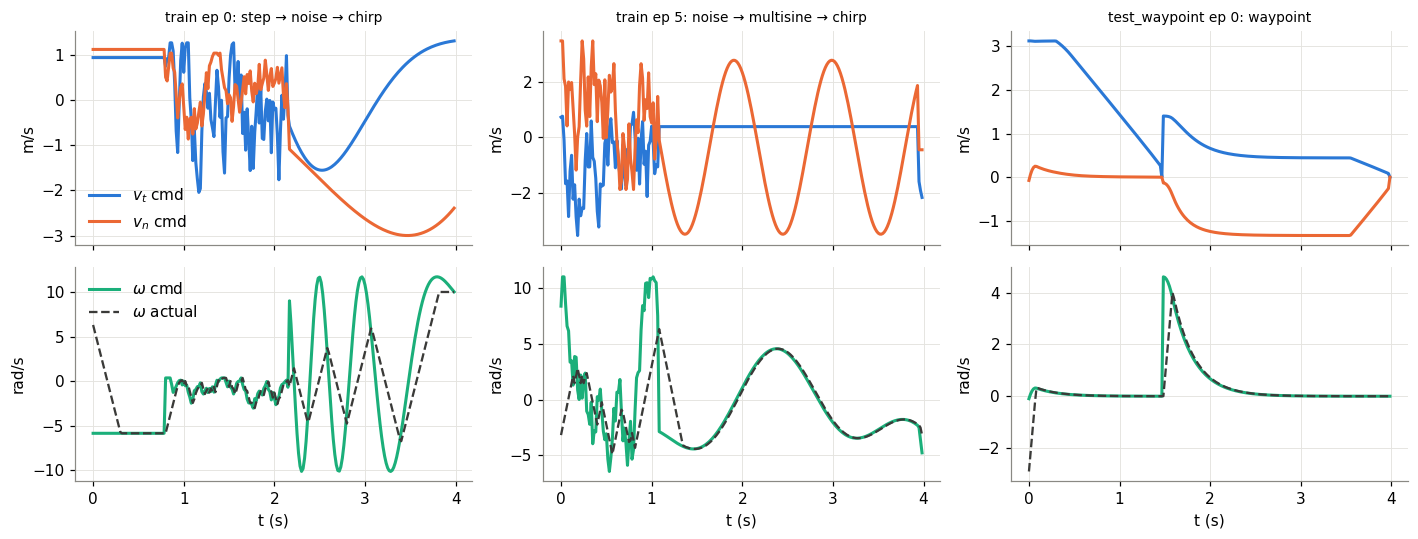

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharex=True)
t = np.arange(240) * data.DT
for j, (name, e) in enumerate([("train", 0), ("train", 5), ("test_waypoint", 0)]):
    ep = DS[name].episodes()[e, :240]
    seg = [data.SEGMENTS[int(s)] for s in ep[:, data.C["seg"]]]
    ax = axes[0, j]
    ax.plot(t, ep[:, data.C["vt_cmd"]], color=COL["B1"], label="$v_t$ cmd")
    ax.plot(t, ep[:, data.C["vn_cmd"]], color=COL["B2"], label="$v_n$ cmd")
    ax.set_title(f"{name} ep {e}: " + " → ".join(dict.fromkeys(seg)), fontsize=9)
    ax.set_ylabel("m/s")
    axes[1, j].plot(t, ep[:, data.C["w_cmd"]], color=COL["M1"], label="$\\omega$ cmd")
    axes[1, j].plot(t, ep[:, data.C["omega"]], color=COL["sim"], ls="--", lw=1.5, label="$\\omega$ actual")
    axes[1, j].set_ylabel("rad/s"); axes[1, j].set_xlabel("t (s)")
axes[0, 0].legend(); axes[1, 0].legend(); fig.tight_layout()

## 3. Data analysis

### 3.1 Sanity checks

In [3]:
rows = []
for n in SPLITS:
    ep = DS[n].episodes()
    s = data.states(ep)
    cmd = data.commands(ep)
    pred = ref.step(T[n]["s0"], T[n]["u"])
    err = np.abs(pred - T[n]["s1"]); err[:, 2] = np.abs(data.wrap(pred[:, 2] - T[n]["s1"][:, 2]))
    rows.append(dict(split=n, episodes=DS[n].n_episodes, transitions=len(T[n]["z"]),
                     nan_states=int(np.isnan(s).sum()), nan_cmds_except_last=int(np.isnan(cmd[:, :-1]).sum()),
                     tick_ok=bool(np.all(np.diff(ep[:, :, data.C["tick"]], axis=1) == 1)),
                     theta_in_range=bool((s[..., 2] > -np.pi).all() and (s[..., 2] <= np.pi).all()),
                     max_err_vs_reference=float(err.max())))
display(pd.DataFrame(rows).set_index("split"))
print("sha256(train.npy) =", hashlib.sha256(open("data/train.npy", "rb").read()).hexdigest()[:16], "…",
      "(regenerating with seed 1 gave the identical hash)")

,episodes,transitions,nan_states,nan_cmds_except_last,tick_ok,theta_in_range,max_err_vs_reference
split,,,,,,,
train,2000,1200000,0,0,True,True,2.5105e-14
val,200,120000,0,0,True,True,2.4869e-14
test_id,200,120000,0,0,True,True,2.4758e-14
test_waypoint,200,120000,0,0,True,True,2.2149e-14


sha256(train.npy) = c6a4835675dc3734 … (regenerating with seed 1 gave the identical hash)


* No NaN or inf; the ticks are consecutive; θ is in $(-\pi, \pi]$.
* **Timing alignment confirmed:** an independent numpy reference of the update law reproduces every transition
  $(s_k, u_k) \to s_{k+1}$ to ~1e-14. So the rows mean what we think (state *before* the step and the command applied in that step),
  and the frames and clamps are right.
* **Determinism:** generating `train` twice with the same seed gives a byte-identical file.

### 3.2 Descriptive statistics (train)

In [4]:
z = pd.DataFrame(T["train"]["z"], columns=data.FEATURES)
d = pd.DataFrame(T["train"]["d"], columns=data.TARGETS)
display(z.describe(percentiles=[.01, .5, .99]).T.drop(columns="count"))
display(d.describe(percentiles=[.01, .5, .99]).T.drop(columns="count"))
segs = pd.DataFrame({n: pd.Series(T[n]["seg"]).map(dict(enumerate(data.SEGMENTS))).value_counts(normalize=True)
                     for n in SPLITS}).fillna(0)
display(segs.style.format("{:.1%}").set_caption("Fraction of transitions per signal type"))

,mean,std,min,1%,50%,99%,max
u_b,0.0003,0.9014,-3.5000,-2.3884,0.0,2.3751,3.5000
v_b,-0.0049,0.9004,-3.5000,-2.3822,0.0,2.4106,3.4999
omega,-0.0671,4.3737,-10.0000,-10.0000,0.0,10.0000,10.0000
vt_cmd,0.0078,1.3637,-4.5495,-3.5392,-0.0,3.5952,4.5346
vn_cmd,-0.0153,1.3577,-4.5028,-3.5544,-0.0,3.5696,4.5326
w_cmd,-0.0680,5.0940,-16.6550,-12.3729,0.0,12.3956,16.6653


,mean,std,min,1%,50%,99%,max
du_b,2.1155e-04,0.0624,-0.1000,-0.0999,0.0,0.0999,0.1000
dv_b,-4.5297e-04,0.0620,-0.1000,-0.0999,0.0,0.0999,0.1000
domega,-6.3079e-05,0.3810,-0.6667,-0.6667,0.0,0.6667,0.6667
dx_b,6.4902e-06,0.0150,-0.0583,-0.0398,-0.0,0.0396,0.0583
dy_b,-8.5803e-05,0.0150,-0.0583,-0.0397,0.0,0.0402,0.0583
dtheta,-1.1168e-03,0.0728,-0.1667,-0.1667,0.0,0.1667,0.1667


,train,val,test_id,test_waypoint
chirp,15.6%,16.0%,13.5%,0.0%
idle,7.3%,7.4%,6.4%,0.0%
multisine,30.4%,28.4%,30.0%,0.0%
noise,22.0%,22.2%,24.2%,0.0%
step,24.8%,26.0%,25.8%,0.0%
waypoint,0.0%,0.0%,0.0%,100.0%


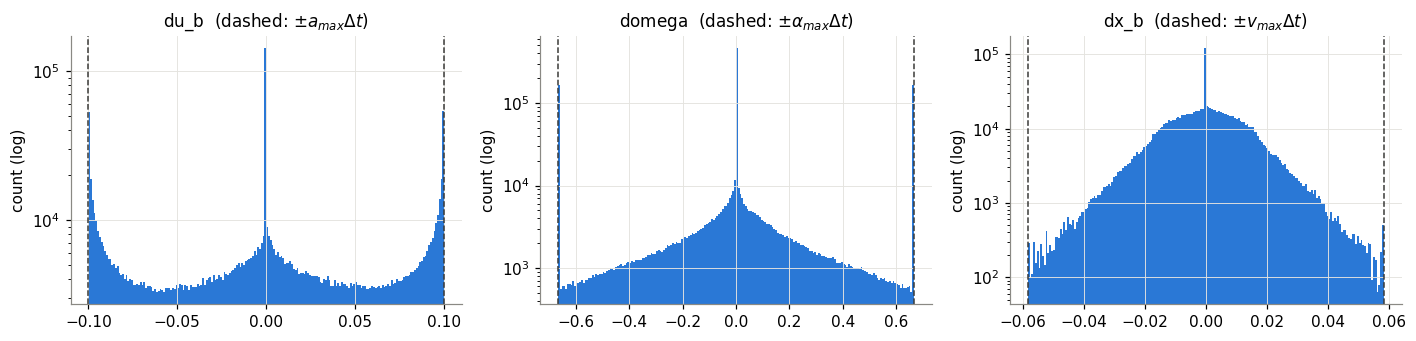

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (col, lim, lab) in zip(axes, [("du_b", 6 * data.DT, "$a_{max}\\Delta t$"), ("domega", 40 * data.DT, "$\\alpha_{max}\\Delta t$"),
                                      ("dx_b", 3.5 * data.DT, "$v_{max}\\Delta t$")]):
    ax.hist(d[col], bins=200, color=COL["B1"], log=True)
    for sgn in (-1, 1): ax.axvline(sgn * lim, color=COL["sim"], ls="--", lw=1)
    ax.set_title(f"{col}  (dashed: ±{lab})"); ax.set_ylabel("count (log)")
fig.tight_layout()

The targets are **bounded exactly at ±$a_{max}\Delta t$ = ±0.1 m/s and ±$\alpha_{max}\Delta t$ = ±0.667 rad/s**,
with large peaks at those bounds. Most transitions sit *on* the clamp, which is the nonlinearity the network has to learn.

### 3.3 Coverage of the input space

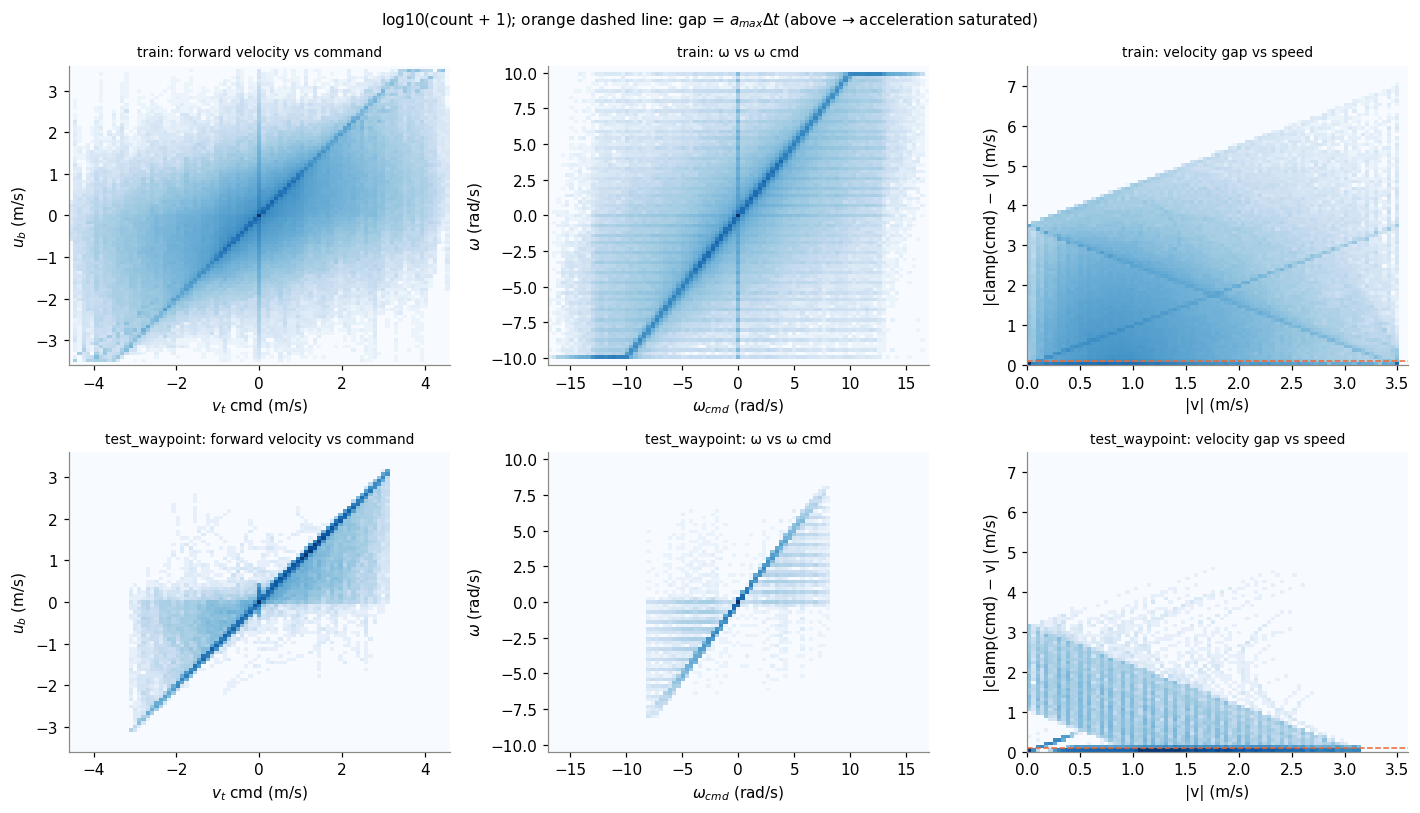

In [6]:
def h2(ax, x, y, bins, title, xl, yl):
    H, xe, ye = np.histogram2d(x, y, bins=bins)
    ax.pcolormesh(xe, ye, np.log10(H.T + 1), cmap="Blues", shading="auto"); ax.grid(False)
    ax.set_title(title, fontsize=9); ax.set_xlabel(xl); ax.set_ylabel(yl)

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for r, n in enumerate(["train", "test_waypoint"]):
    zz = T[n]["z"]; gap = LAB[n][2]; speed = np.hypot(zz[:, 0], zz[:, 1])
    h2(axes[r, 0], zz[:, 3], zz[:, 0], [np.linspace(-4.6, 4.6, 90), np.linspace(-3.6, 3.6, 90)], f"{n}: forward velocity vs command",
       "$v_t$ cmd (m/s)", "$u_b$ (m/s)")
    h2(axes[r, 1], zz[:, 5], zz[:, 2], [np.linspace(-17, 17, 90), np.linspace(-10.5, 10.5, 90)], f"{n}: ω vs ω cmd",
       "$\\omega_{cmd}$ (rad/s)", "$\\omega$ (rad/s)")
    h2(axes[r, 2], speed, gap, [np.linspace(0, 3.6, 90), np.linspace(0, 7.5, 90)], f"{n}: velocity gap vs speed",
       "|v| (m/s)", "|clamp(cmd) − v| (m/s)")
    axes[r, 2].axhline(6 * data.DT, color=COL["B2"], lw=1, ls="--")
fig.suptitle("log10(count + 1); orange dashed line: gap = $a_{max}\\Delta t$ (above → acceleration saturated)", fontsize=10)
fig.tight_layout()

* **Train** covers the command space densely, including commands above the limits (|cmd| up to 4.5 m/s and 16.7 rad/s).
  Speed coverage is thinner above ~2.5 m/s (99th percentile of $|u_b|$ ≈ 2.4 m/s): high speeds are rare.
* **test_waypoint** sits on a narrow band: velocity close to the command (small gap), no commands above the limits,
  and smaller ω. It is a *subset* of the train support, but concentrated in a region with lower train density.

### 3.4 Structure of the dynamics seen in the data

,estimated from data,configuration
a_max (m/s²),6.0,6.0
v_max (m/s),3.5,3.5
α_max (rad/s²),40.0,40.0
ω_max (rad/s),10.0,10.0


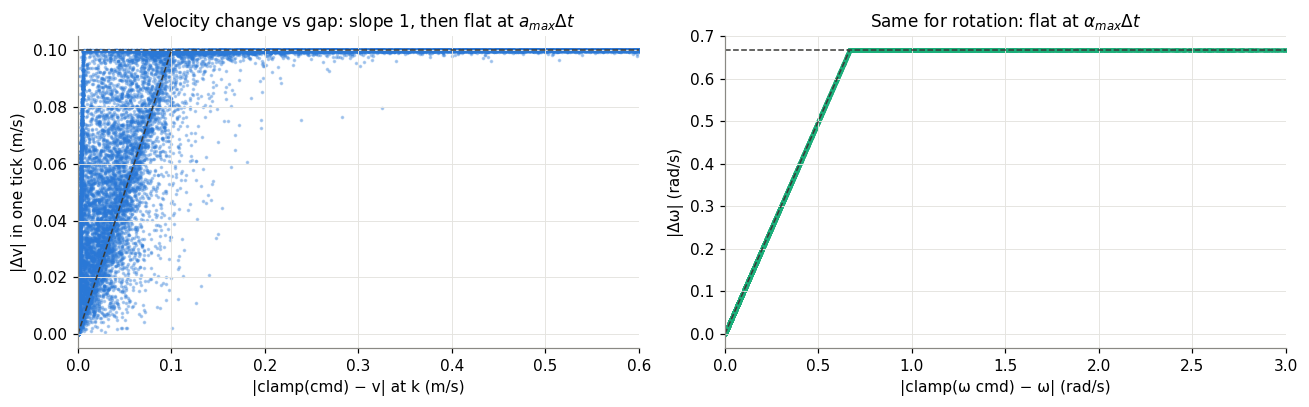

In [7]:
t = T["train"]; gap = LAB["train"][2]
dv = np.hypot(t["d"][:, 0], t["d"][:, 1]); dw = np.abs(t["d"][:, 2])
wgap = np.abs(np.clip(t["u"][:, 2], -10, 10) - t["s0"][:, 5])
rng = np.random.default_rng(0); i = rng.choice(len(gap), 60000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(gap[i], dv[i], s=2, alpha=0.3, color=COL["B1"], rasterized=True)
axes[0].plot([0, 0.1], [0, 0.1], color=COL["sim"], ls="--", lw=1); axes[0].axhline(0.1, color=COL["sim"], ls="--", lw=1)
axes[0].set_xlim(0, 0.6); axes[0].set_xlabel("|clamp(cmd) − v| at k (m/s)"); axes[0].set_ylabel("|Δv| in one tick (m/s)")
axes[0].set_title("Velocity change vs gap: slope 1, then flat at $a_{max}\\Delta t$")
axes[1].scatter(wgap[i], dw[i], s=2, alpha=0.3, color=COL["M1"], rasterized=True)
axes[1].plot([0, 0.667], [0, 0.667], color=COL["sim"], ls="--", lw=1); axes[1].axhline(0.667, color=COL["sim"], ls="--", lw=1)
axes[1].set_xlim(0, 3); axes[1].set_xlabel("|clamp(ω cmd) − ω| (rad/s)"); axes[1].set_ylabel("|Δω| (rad/s)")
axes[1].set_title("Same for rotation: flat at $\\alpha_{max}\\Delta t$"); fig.tight_layout()

est = pd.DataFrame({
    "estimated from data": [dv.max() / data.DT, np.hypot(t["s1"][:, 3], t["s1"][:, 4]).max(), dw.max() / data.DT, np.abs(t["s1"][:, 5]).max()],
    "configuration": [6.0, 3.5, 40.0, 10.0]}, index=["a_max (m/s²)", "v_max (m/s)", "α_max (rad/s²)", "ω_max (rad/s)"])
display(est)

The data shows the expected physics: $|\Delta v|$ follows the gap with slope 1 until $a_{max}\Delta t$, then stays flat.
The **limits estimated purely from the data match the configuration exactly**. The bend near the corner is smooth because the
clamp can switch off *inside* the tick (17 substeps), which is the `settling` regime.

**Regimes.** Each transition gets exactly one translational regime (`stopped`, `braking`, `sat_accel`, `settling`, `cruise`, see
`nn_sim/regimes.py`) plus tags that may overlap.

In [8]:
rows = {}
for n in SPLITS:
    reg, tags, _ = LAB[n]
    r = {name: (reg == k).mean() for k, name in enumerate(regimes.TRANSLATION)}
    r.update({k: v.mean() for k, v in tags.items()})
    rows[n] = r
display(pd.DataFrame(rows).style.format("{:.1%}").set_caption("Fraction of transitions per regime / tag"))

,train,val,test_id,test_waypoint
stopped,8.3%,8.0%,7.7%,2.8%
braking,2.7%,2.9%,2.7%,1.8%
sat_accel,69.8%,70.0%,69.1%,23.6%
settling,16.4%,16.6%,17.4%,71.7%
cruise,2.7%,2.6%,3.2%,0.0%
cmd_above_limit,7.6%,8.2%,7.4%,0.0%
at_max_speed,0.7%,0.6%,0.5%,0.0%
rot_saturated,27.3%,28.3%,28.5%,5.6%
turn_and_move,58.4%,58.7%,57.7%,27.3%


In [9]:
# How much a linear model explains, per regime (least squares on raw z, train)
t = T["train"]; Z = np.c_[t["z"], np.ones(len(t["z"]))]
W = np.linalg.lstsq(Z, t["d"], rcond=None)[0]; E = t["d"] - Z @ W; var = t["d"].var(0)
reg = LAB["train"][0]
r2 = {"all": 1 - (E**2).mean(0) / var}
for k, name in enumerate(regimes.TRANSLATION):
    m = reg == k
    r2[name] = 1 - (E[m]**2).mean(0) / np.maximum(t["d"][m].var(0), 1e-12)
display(pd.DataFrame(r2, index=data.TARGETS).T.style.format("{:.3f}").set_caption("Linear fit R² per target (within each regime)"))

,du_b,dv_b,domega,dx_b,dy_b,dtheta
all,0.595,0.595,0.524,0.999,0.999,0.999
stopped,-512.014,-2524.044,0.609,-1.110,-10.987,1.000
braking,0.544,0.549,0.647,0.999,0.999,0.998
sat_accel,0.641,0.640,0.519,0.999,0.999,0.999
settling,0.037,0.041,0.515,0.999,0.999,0.999
cruise,-12345.368,-6161.450,0.764,1.000,1.000,0.746


* A linear model explains only **~60% of the variance of Δv and ~52% of Δω**: the clamp is the main nonlinearity.
  The pose increments are explained almost entirely (R² ≈ 0.999), because they are dominated by $v\,\Delta t$.
* In `cruise`, linear is almost perfect; in `sat_accel` and `braking` it is poor (Δv is constant in magnitude, $a_{max}\Delta t$ in
  the direction of the gap, which is not a linear function of z).

**Rotation-translation coupling.** The command is in the robot frame, so while the robot turns, the target velocity
rotates in the world frame *within* the tick. That is the source of second-order effects in $dx_b, dy_b$.

In [10]:
for n in ["train", "test_waypoint"]:
    w = np.abs(T[n]["s0"][:, 5]) * data.DT
    print(f"{n:14s} turn_and_move = {LAB[n][1]['turn_and_move'].mean():.1%};  rotation per tick |ω|Δt: "
          f"median {np.degrees(np.median(w)):.2f}°, p90 {np.degrees(np.percentile(w, 90)):.2f}°, max {np.degrees(w.max()):.2f}°")

train          turn_and_move = 58.4%;  rotation per tick |ω|Δt: median 2.43°, p90 7.66°, max 9.55°
test_waypoint  turn_and_move = 27.3%;  rotation per tick |ω|Δt: median 0.27°, p90 2.96°, max 7.62°


### 3.5 Train vs test distributions

,KL(test ‖ train) (nats),test samples in train bins with < 100 samples
test_id,0.0204,0.0352
test_waypoint,1.3284,0.0025


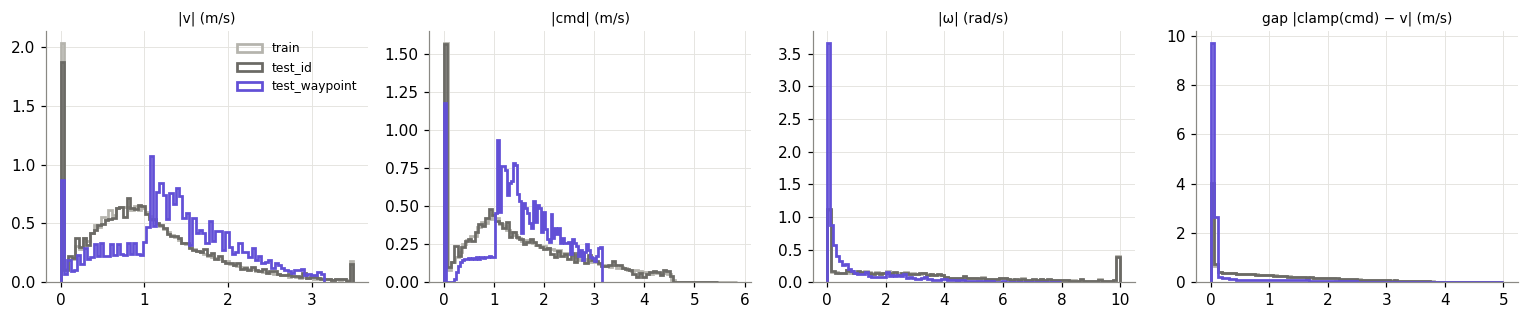

In [11]:
feats = {"|v| (m/s)": lambda t: np.hypot(t["z"][:, 0], t["z"][:, 1]),
         "|cmd| (m/s)": lambda t: np.hypot(t["z"][:, 3], t["z"][:, 4]),
         "|ω| (rad/s)": lambda t: np.abs(t["z"][:, 2]),
         "gap |clamp(cmd) − v| (m/s)": None}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (name, fn) in zip(axes, feats.items()):
    for n in ["train", "test_id", "test_waypoint"]:
        x = LAB[n][2] if fn is None else fn(T[n])
        ax.hist(x, bins=80, range=(0, 5 if fn is None else None) if fn is None else None, density=True,
                histtype="step", lw=1.8, color=COL[n], label=n)
    ax.set_title(name, fontsize=9)
axes[0].legend(fontsize=8); fig.tight_layout()

# Shift on a binned 3D summary: (|v|, gap, |ω_cmd − ω|)
def summary(n):
    t = T[n]
    return np.c_[np.hypot(t["z"][:, 0], t["z"][:, 1]), LAB[n][2], np.abs(np.clip(t["u"][:, 2], -10, 10) - t["s0"][:, 5])]
edges = [np.linspace(0, 3.6, 19), np.r_[np.linspace(0, 1, 11), 8], np.r_[np.linspace(0, 4, 11), 30]]
Htr = np.histogramdd(summary("train"), bins=edges)[0]; Ptr = (Htr + 1e-3) / (Htr + 1e-3).sum()
rows = {}
for n in ["test_id", "test_waypoint"]:
    S = summary(n); H = np.histogramdd(S, bins=edges)[0]; P = H / H.sum()
    idx = tuple(np.clip(np.searchsorted(e, S[:, k], side="right") - 1, 0, len(e) - 2) for k, e in enumerate(edges))
    rows[n] = {"KL(test ‖ train) (nats)": float((P[P > 0] * np.log(P[P > 0] / Ptr[P > 0])).sum()),
               "test samples in train bins with < 100 samples": float((Htr[idx] < 100).mean())}
display(pd.DataFrame(rows).T)

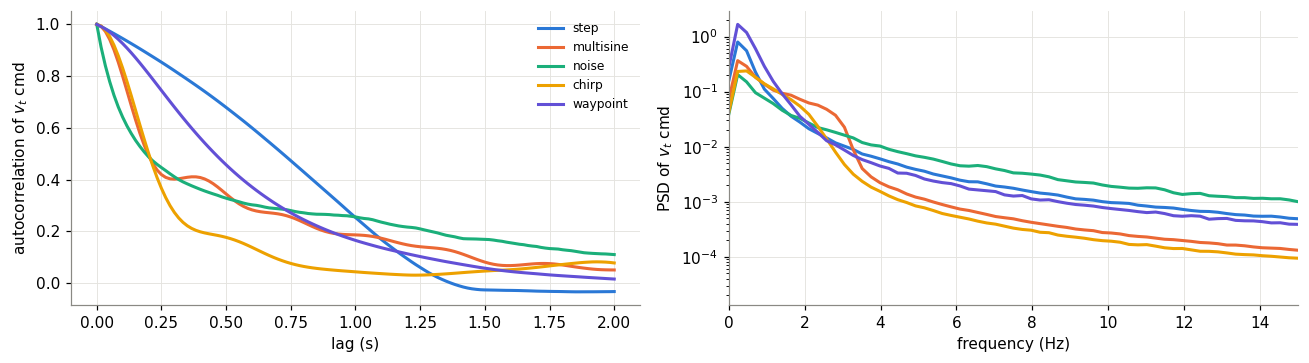

In [12]:
# Autocorrelation and spectrum of the forward command per signal type (train)
from scipy.signal import welch
ep = DS["train"].episodes()[:, :-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
order = ["step", "multisine", "noise", "chirp", "idle", "waypoint"]
colors = dict(zip(order, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]))
lags = np.arange(0, 121)
for name in order:
    k = data.SEGMENTS.index(name)
    src = DS["test_waypoint"].episodes()[:, :-1] if name == "waypoint" else ep
    x = src[..., data.C["vt_cmd"]]; m = src[..., data.C["seg"]] == k
    if name == "idle":
        continue  # constant zero: autocorrelation undefined
    xs = np.where(m, x - x[m].mean(), np.nan)
    ac = [np.nanmean(xs[:, :xs.shape[1] - L] * xs[:, L:]) / np.nanvar(xs) for L in lags]
    axes[0].plot(lags * data.DT, ac, color=colors[name], label=name)
    seq = x[m.all(1)] if m.all(1).any() else None
    f, P = welch(np.where(m, x, 0), fs=60, nperseg=256, axis=1)
    axes[1].semilogy(f, P.mean(0) + 1e-12, color=colors[name], label=name)
axes[0].set_xlabel("lag (s)"); axes[0].set_ylabel("autocorrelation of $v_t$ cmd"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("frequency (Hz)"); axes[1].set_ylabel("PSD of $v_t$ cmd"); axes[1].set_xlim(0, 15)
fig.tight_layout()

### 3.6 Decisions taken from the analysis

| Observation | Decision |
|---|---|
| Targets are bounded (±$a_{max}\Delta t$ …) with no heavy tails; scales differ by ~10× between Δv, Δω and pose | plain **standardization** of z and Δ (train mean/std), equal weight per standardized component |
| Linear R² of Δv ≈ 0.6: the clamp is the main nonlinearity | a nonlinear model is needed; the linear model is kept as a reference (B2) |
| `at_max_speed` (0.7%) and `cruise` (2.7%) are rare in train; waypoint lives mostly in `settling` | **no rebalancing** this session; error by regime (metric 3) checks whether the rare regimes are the weak spots |
| f is invariant to translation/rotation | robot-frame features without x, y, θ (section 4) |
| Coverage is broad (test samples rarely fall in empty train bins) | data volume and excitation are kept; the learning curve (metric 6) checks whether more data would help |

## 4. Representation and models

**Features** (robot frame at k): $z_k = (u_b, v_b, \omega, v_t, v_n, \omega_{cmd})$, with no $x, y, \theta$.
**Targets:** $\Delta_k = (\Delta u_b, \Delta v_b, \Delta\omega, dx_b, dy_b, d\theta)$, the velocity change and pose increment expressed in the k frame.
The next state is obtained by composing $\Delta_k$ with $s_k$ (exact round trip verified to 1e-15).

| Id | Model | Training |
|---|---|---|
| B1 | constant velocity: Δv = 0, pose += v Δt | none |
| B2 | linear regression on standardized z | least squares (closed form) |
| M1 | MLP 6 → 256 → 256 → 256 → 6, SiLU | one-step MSE, Adam 1e-3 cosine, 12k steps × 4096, best val checkpoint; 5 seeds (seed 0 = M1) |
| M2 | M1 seed 0, fine-tuned | open-loop rollout loss over 60 ticks (1 s) through BPTT + one-step loss, Adam 3e-4, 3k steps × 512 windows |

Rollout loss: $L_N=\frac1N\sum_j \left[(\|\hat p-p\|/1\,\text{cm})^2+(|\hat\theta-\theta|/0.01)^2+(\|\hat v-v\|/5\,\text{cm/s})^2+(|\hat\omega-\omega|/0.1)^2\right]$.

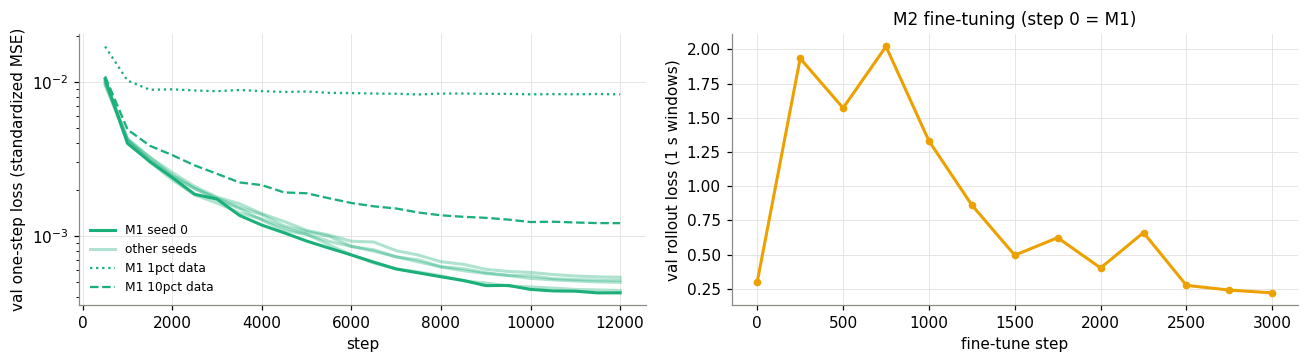

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for s in range(5):
    h = json.load(open(f"results/train_M1_s{s}.json"))["history"]
    axes[0].semilogy([x["step"] for x in h], [x["val"] for x in h], color=COL["M1"], alpha=1 if s == 0 else 0.35,
                     label="M1 seed 0" if s == 0 else ("other seeds" if s == 1 else None))
for frac, ls in [("1pct", ":"), ("10pct", "--")]:
    h = json.load(open(f"results/train_M1_{frac}.json"))["history"]
    axes[0].semilogy([x["step"] for x in h], [x["val"] for x in h], color=COL["M1"], ls=ls, lw=1.5, label=f"M1 {frac} data")
axes[0].set_xlabel("step"); axes[0].set_ylabel("val one-step loss (standardized MSE)"); axes[0].legend(fontsize=8)
h = json.load(open("results/train_M2.json"))["history"]
axes[1].plot([x["step"] for x in h], [x["val"] for x in h], color=COL["M2"], marker="o", ms=4)
axes[1].set_xlabel("fine-tune step"); axes[1].set_ylabel("val rollout loss (1 s windows)"); axes[1].set_title("M2 fine-tuning (step 0 = M1)")
fig.tight_layout()

## 5. Results

All metrics are computed on **test_id** (same distribution as training) and **test_waypoint** (AI-like driving, never trained on).

### Metric 1 — one-step error

In [14]:
units = dict(zip(data.TARGETS, ["mm/s", "mm/s", "mrad/s", "µm", "µm", "µrad"]))
rows = []
for m in ["B1", "B2", "M1", "M2"]:
    for s in ["test_id", "test_waypoint"]:
        o = EVAL["one_step"][m][s]
        r = {"model": m, "split": s, "NMSE (std. units)": o["nmse"]}
        r.update({f"RMSE {t} ({units[t]})": v * 1e3 if units[t].startswith("m") else v * 1e6 for t, v in zip(data.TARGETS, o["rmse"])})
        rows.append(r)
df = pd.DataFrame(rows).set_index(["model", "split"])
display(df.style.format("{:.3g}"))
r2 = pd.DataFrame({m: EVAL["one_step"][m]["test_id"]["r2"] for m in ["B1", "B2", "M1", "M2"]}, index=data.TARGETS).T
display(r2.style.format("{:.5f}").set_caption("R² per target, test_id"))

,du_b,dv_b,domega,dx_b,dy_b,dtheta
B1,-0.00011,-0.00007,-0.00002,0.99864,0.99872,0.99747
B2,0.58805,0.58400,0.51771,0.99943,0.99945,0.99866
M1,0.99883,0.99887,0.99932,0.99997,0.99997,0.99996
M2,0.99877,0.99879,0.99911,0.99995,0.99996,0.99997


### Metric 2 — open-loop rollout error (main metric)

Start from the true state at 6 points per test episode (t = 0, 1, …, 5 s; 1200 rollouts per split). The model receives **only the commands**
for 5 s and feeds its own predictions back.

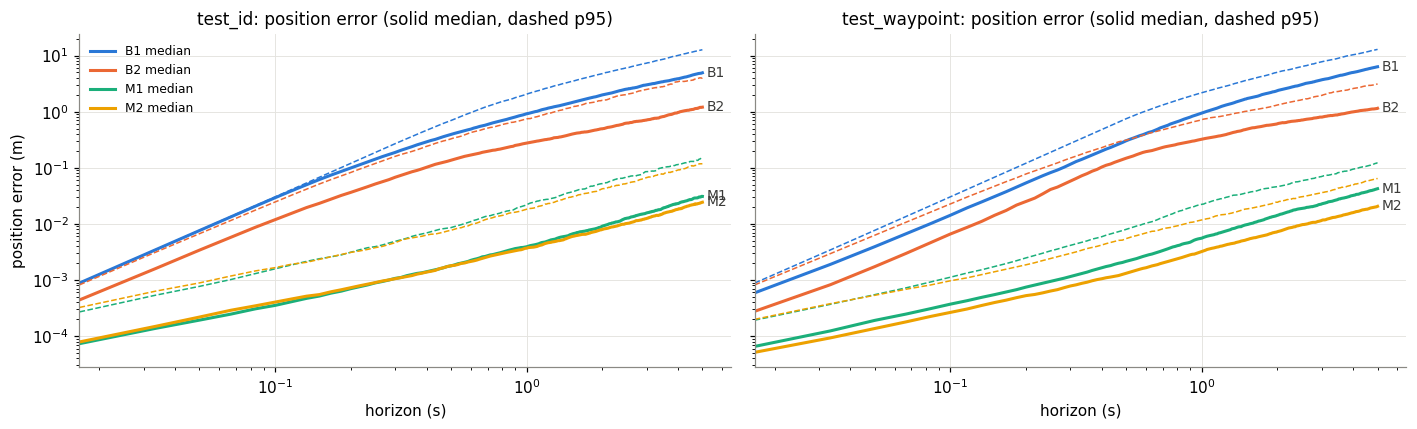

In [15]:
t = np.arange(301) * data.DT
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, s in zip(axes, ["test_id", "test_waypoint"]):
    for m in ["B1", "B2", "M1", "M2"]:
        med, p95 = CURVES[f"roll_med_{m}_{s}"][:, 0], CURVES[f"roll_p95_{m}_{s}"][:, 0]
        ax.loglog(t[1:], med[1:], color=COL[m], label=f"{m} median")
        ax.loglog(t[1:], p95[1:], color=COL[m], lw=1, ls="--")
        ax.text(t[-1] * 1.04, med[-1], m, color="#3a3a38", fontsize=9, va="center")
    ax.set_title(f"{s}: position error (solid median, dashed p95)"); ax.set_xlabel("horizon (s)"); ax.set_xlim(t[1], 6.5)
axes[0].set_ylabel("position error (m)"); axes[0].legend(fontsize=8, loc="upper left"); fig.tight_layout()

rows = []
for m in ["B1", "B2", "M1", "M2"]:
    for s in ["test_id", "test_waypoint"]:
        o = EVAL["rollout"][m][s]; r = {"model": m, "split": s}
        for h in ["0.1s", "0.5s", "1.0s", "2.0s", "5.0s"]:
            r[f"pos {h} med (mm)"] = o[h]["median"][0] * 1e3
        r["pos 5s p95 (mm)"] = o["5.0s"]["p95"][0] * 1e3
        r["θ 5s med (mrad)"] = o["5.0s"]["median"][1] * 1e3
        r["v 5s med (mm/s)"] = o["5.0s"]["median"][2] * 1e3
        r["growth exponent p"] = o["growth_exponent_pos"]
        rows.append(r)
display(pd.DataFrame(rows).set_index(["model", "split"]).style.format("{:.3g}").set_caption("err(t) ∝ t^p fitted on the median, 0.1–5 s"))

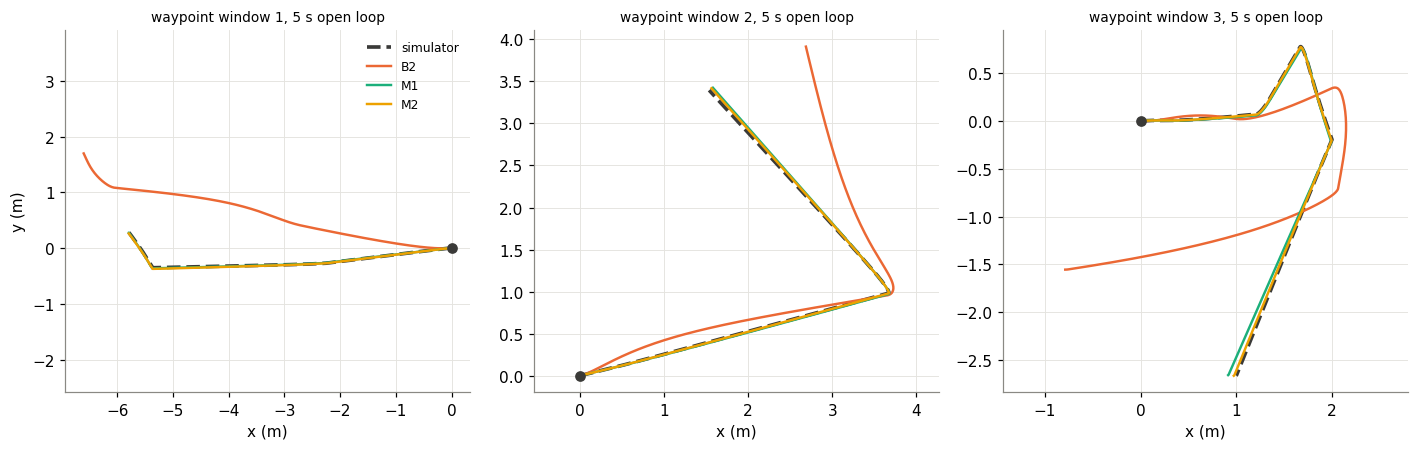

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
true = CURVES["traj_true"]
for j, ax in enumerate(axes):
    ax.plot(true[j, :, 0], true[j, :, 1], color=COL["sim"], ls="--", lw=2.4, label="simulator")
    for m in ["B2", "M1", "M2"]:
        tr = CURVES[f"traj_{m}"][j]; ax.plot(tr[:, 0], tr[:, 1], color=COL[m], lw=1.6, label=m)
    ax.plot(0, 0, "o", color=COL["sim"], ms=6); ax.set_aspect("equal", "datalim"); ax.set_title(f"waypoint window {j + 1}, 5 s open loop", fontsize=9)
    ax.set_xlabel("x (m)")
axes[0].set_ylabel("y (m)"); axes[0].legend(fontsize=8); fig.tight_layout()

### Metric 3 — error by regime

One-step velocity error $\sqrt{\overline{\|\Delta\hat v-\Delta v\|^2}}$ (mm/s) per regime. Fraction = share of transitions in the split.

,fraction test_id,fraction waypoint,B2 id,B2 wp,M1 id,M1 wp,M2 id,M2 wp
regime,,,,,,,,
stopped,7.7%,2.8%,0.48,0.14,0.30,0.21,0.70,0.18
braking,2.7%,1.8%,65.28,83.81,1.82,2.80,1.91,2.76
sat_accel,69.1%,23.6%,60.45,54.16,2.54,3.66,2.52,3.40
settling,17.4%,71.7%,56.36,36.16,4.78,2.68,5.09,3.27
cruise,3.2%,0.0%,9.89,–,3.40,–,3.56,–
cmd_above_limit,7.4%,0.0%,67.04,–,7.39,–,7.09,–
at_max_speed,0.5%,0.0%,36.57,–,10.68,–,10.10,–
rot_saturated,28.5%,5.6%,59.57,37.87,2.82,1.38,2.93,1.31
turn_and_move,57.7%,27.3%,60.86,46.04,3.19,3.86,3.20,4.15


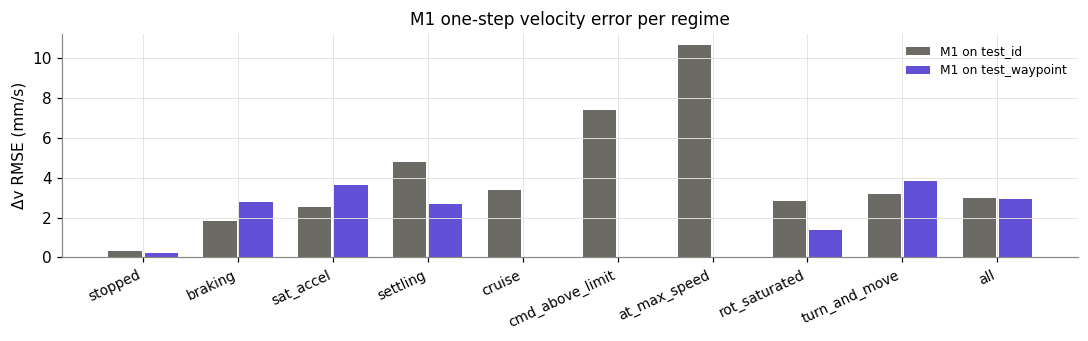

In [17]:
order = regimes.TRANSLATION + regimes.TAGS + ["all"]
rows = []
for name in order:
    r = {"regime": name, "fraction test_id": EVAL["regimes"]["M1"]["test_id"][name]["frac"],
         "fraction waypoint": EVAL["regimes"]["M1"]["test_waypoint"][name]["frac"]}
    for m in ["B2", "M1", "M2"]:
        for s, lab in [("test_id", "id"), ("test_waypoint", "wp")]:
            v = EVAL["regimes"][m][s][name].get("vel_rmse")
            r[f"{m} {lab}"] = np.nan if v is None else v * 1e3
    rows.append(r)
reg_df = pd.DataFrame(rows).set_index("regime")
display(reg_df.style.format({c: "{:.1%}" for c in reg_df.columns[:2]} | {c: "{:.2f}" for c in reg_df.columns[2:]}, na_rep="–"))

fig, ax = plt.subplots(figsize=(10, 3.2))
x = np.arange(len(order)); w = 0.38
for k, (s, col) in enumerate([("test_id", COL["test_id"]), ("test_waypoint", COL["test_waypoint"])]):
    vals = [reg_df.loc[n, f"M1 {'id' if s == 'test_id' else 'wp'}"] for n in order]
    ax.bar(x + (k - 0.5) * w, vals, w * 0.92, color=col, label=f"M1 on {s}")
ax.set_xticks(x, order, rotation=25, ha="right", fontsize=9); ax.set_ylabel("Δv RMSE (mm/s)")
ax.set_title("M1 one-step velocity error per regime"); ax.legend(fontsize=8); fig.tight_layout()

### Metric 4 — physical properties (step responses)

The robot starts at rest and receives a constant command. The simulator response comes from the validated reference.

,t90 sim (s),t90 B2,steady B2,overshoot B2,t90 M1,steady M1,overshoot M1,t90 M2,steady M2,overshoot M2,steady sim
test,,,,,,,,,,,
translation cmd 0.5,0.083,0.800,0.501,0.010,0.083,0.500,0.003,0.083,0.500,0.003,0.500
translation cmd 1.0,0.167,0.800,1.005,0.013,0.150,1.000,0.002,0.150,1.001,0.002,1.000
translation cmd 2.0,0.317,0.783,2.013,0.014,0.317,2.000,0.001,0.317,2.002,0.002,2.000
translation cmd 3.0,0.467,0.783,3.021,0.015,0.450,3.004,0.001,0.450,3.006,0.002,3.000
translation cmd 3.5,0.533,0.783,3.525,0.015,0.533,3.474,0.000,0.533,3.472,0.000,3.500
translation cmd 4.5,0.533,0.433,4.533,0.305,0.550,3.506,0.002,0.550,3.495,0.000,3.500
rotation cmd 1.0,0.033,0.400,0.956,0.000,0.033,1.000,0.011,0.033,0.999,0.018,1.000
rotation cmd 3.0,0.083,0.400,2.871,0.000,0.083,3.001,0.003,0.083,2.999,0.005,3.000
rotation cmd 6.0,0.150,0.400,5.743,0.000,0.150,5.999,0.000,0.150,5.998,0.000,6.000


,B2,M1,M2,simulator
max_speed,4.533,3.506,3.495,3.500
max_accel,11.892,5.936,5.953,6.000
max_omega,12.445,9.997,9.984,10.000
max_alpha,78.454,42.565,41.447,40.000


,B2,M1,M2,simulator
time,1.000,0.500,0.500,0.500
distance,1.063,0.748,0.750,0.749


arc final position error (m): {'B2': 0.8695, 'M1': 0.0282, 'M2': 0.0338}


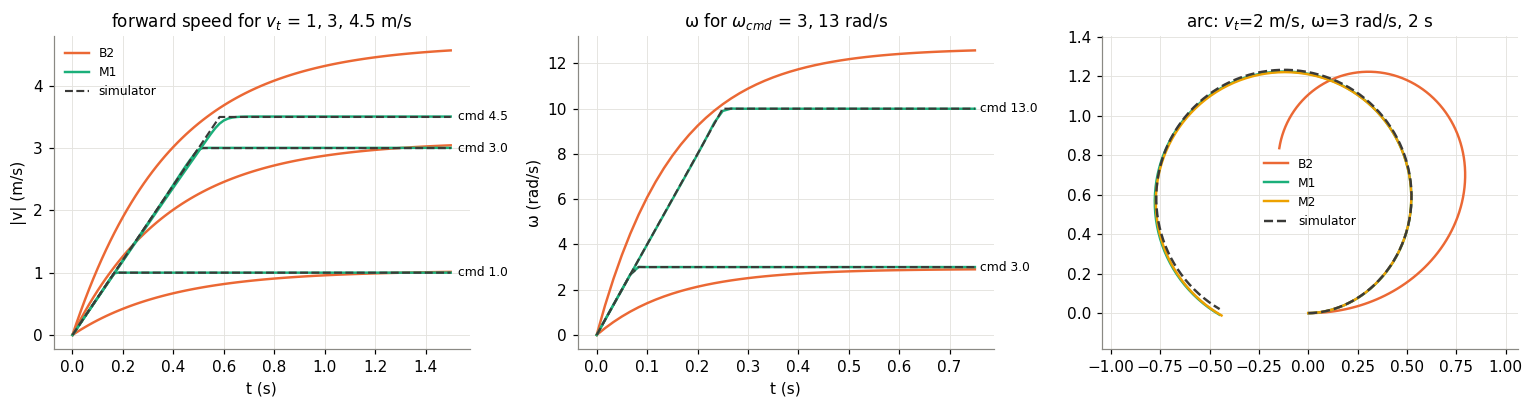

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
tt = np.arange(91) * data.DT
for c in [1.0, 3.0, 4.5]:
    for m, ls in [("B2", "-"), ("M1", "-")]:
        axes[0].plot(tt, CURVES[f"phys_{m}_trans_{c}"][0], color=COL[m], lw=1.6, label=m if c == 1.0 else None)
    axes[0].plot(tt, CURVES[f"phys_M1_trans_{c}"][1], color=COL["sim"], ls="--", lw=1.4, label="simulator" if c == 1.0 else None)
    axes[0].text(tt[-1] + 0.03, min(c, 3.5), f"cmd {c}", fontsize=8, va="center")
axes[0].set_title("forward speed for $v_t$ = 1, 3, 4.5 m/s"); axes[0].set_xlabel("t (s)"); axes[0].set_ylabel("|v| (m/s)"); axes[0].legend(fontsize=8)
tr = np.arange(46) * data.DT
for c in [3.0, 13.0]:
    for m in ["B2", "M1"]:
        axes[1].plot(tr, CURVES[f"phys_{m}_rot_{c}"][0], color=COL[m], lw=1.6)
    axes[1].plot(tr, CURVES[f"phys_M1_rot_{c}"][1], color=COL["sim"], ls="--", lw=1.4)
    axes[1].text(tr[-1] + 0.01, min(c, 10), f"cmd {c}", fontsize=8, va="center")
axes[1].set_title("ω for $\\omega_{cmd}$ = 3, 13 rad/s"); axes[1].set_xlabel("t (s)"); axes[1].set_ylabel("ω (rad/s)")
for m in ["B2", "M1", "M2"]:
    a = CURVES[f"phys_{m}_arc"][0]; axes[2].plot(a[:, 0], a[:, 1], color=COL[m], lw=1.6, label=m)
a = CURVES["phys_M1_arc"][1]; axes[2].plot(a[:, 0], a[:, 1], color=COL["sim"], ls="--", lw=1.6, label="simulator")
axes[2].set_aspect("equal", "datalim"); axes[2].set_title("arc: $v_t$=2 m/s, ω=3 rad/s, 2 s"); axes[2].legend(fontsize=8)
fig.tight_layout()

rows = []
for kind, cmds in [("translation", ["0.5", "1.0", "2.0", "3.0", "3.5", "4.5"]), ("rotation", ["1.0", "3.0", "6.0", "10.0", "13.0"])]:
    for c in cmds:
        r = {"test": f"{kind} cmd {c}"}
        r["t90 sim (s)"] = EVAL["physical"]["M1"][kind][c]["sim"]["t90"]
        for m in ["B2", "M1", "M2"]:
            o = EVAL["physical"][m][kind][c]["nn"]
            r[f"t90 {m}"] = o["t90"]; r[f"steady {m}"] = o["steady"]; r[f"overshoot {m}"] = o["overshoot"]
        r["steady sim"] = EVAL["physical"]["M1"][kind][c]["sim"]["steady"]
        rows.append(r)
display(pd.DataFrame(rows).set_index("test").style.format("{:.3f}", na_rep="–"))
lim = pd.DataFrame({m: EVAL["physical"][m]["effective_limits"]["nn"] for m in ["B2", "M1", "M2"]})
lim["simulator"] = pd.Series(EVAL["physical"]["M1"]["effective_limits"]["sim"])
display(lim.style.format("{:.3f}").set_caption("Effective limits measured on the model's own trajectories"))
br = pd.DataFrame({m: EVAL["physical"][m]["braking_from_3mps"]["nn"] for m in ["B2", "M1", "M2"]})
br["simulator"] = pd.Series(EVAL["physical"]["M1"]["braking_from_3mps"]["sim"])
display(br.style.format("{:.3f}").set_caption("Braking from 3 m/s with zero command: time (s) and distance (m) to < 0.05 m/s"))
print("arc final position error (m):", {m: round(EVAL["physical"][m]["arc_final_pos_error_m"], 4) for m in ["B2", "M1", "M2"]})

### Metric 5 — generalization (does it work on driving it never trained on?)

Ratio = error on test_waypoint / error on test_id (1 = no degradation).

In [19]:
rows = []
for m in ["B1", "B2", "M1", "M2"]:
    rows.append({"model": m,
                 "one-step NMSE id": EVAL["one_step"][m]["test_id"]["nmse"], "one-step NMSE wp": EVAL["one_step"][m]["test_waypoint"]["nmse"],
                 "ratio one-step": EVAL["generalization"][m]["one_step_nmse_ratio"],
                 "pos 1 s id (mm)": EVAL["rollout"][m]["test_id"]["1.0s"]["median"][0] * 1e3,
                 "pos 1 s wp (mm)": EVAL["rollout"][m]["test_waypoint"]["1.0s"]["median"][0] * 1e3,
                 "ratio rollout 1 s": EVAL["generalization"][m]["pos_1s_median_ratio"],
                 "pos 5 s id (mm)": EVAL["rollout"][m]["test_id"]["5.0s"]["median"][0] * 1e3,
                 "pos 5 s wp (mm)": EVAL["rollout"][m]["test_waypoint"]["5.0s"]["median"][0] * 1e3})
display(pd.DataFrame(rows).set_index("model").style.format("{:.3g}"))

,one-step NMSE id,one-step NMSE wp,ratio one-step,pos 1 s id (mm),pos 1 s wp (mm),ratio rollout 1 s,pos 5 s id (mm),pos 5 s wp (mm)
model,,,,,,,,
B1,0.507,0.179,0.353,917,945,1.03,4.93e+03,6.31e+03
B2,0.222,0.0924,0.417,276,323,1.17,1.2e+03,1.15e+03
M1,0.000519,0.000382,0.736,3.91,5.56,1.42,30.9,42.3
M2,0.00058,0.000486,0.838,3.69,3.23,0.876,24.3,20.6


### Metric 6 — data efficiency

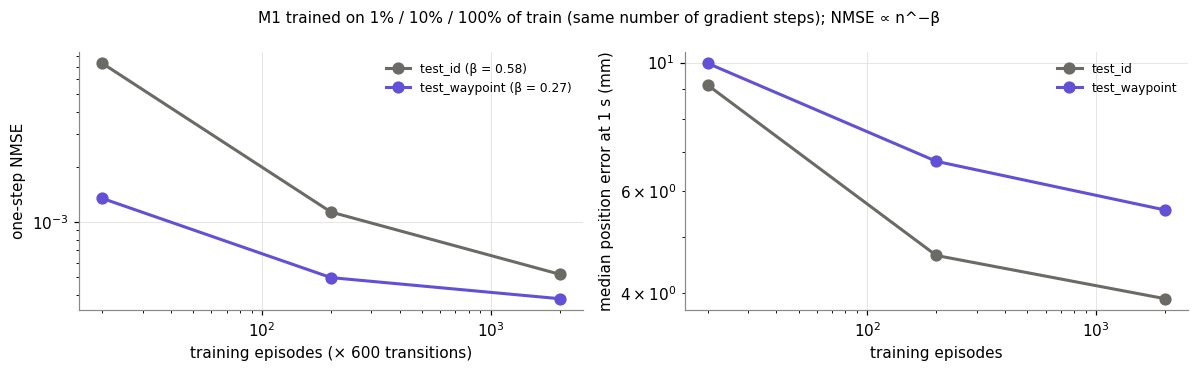

In [20]:
de = EVAL["data_efficiency"]; fr = ["1pct", "10pct", "100pct"]; n = [de[f]["episodes"] for f in fr]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for s in ["test_id", "test_waypoint"]:
    axes[0].loglog(n, [de[f][s]["nmse"] for f in fr], marker="o", ms=7, color=COL[s], label=f"{s} (β = {de['beta_' + s]:.2f})")
    axes[1].loglog(n, [de[f][s]["pos_1s_median"] * 1e3 for f in fr], marker="o", ms=7, color=COL[s], label=s)
axes[0].set_xlabel("training episodes (× 600 transitions)"); axes[0].set_ylabel("one-step NMSE"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("training episodes"); axes[1].set_ylabel("median position error at 1 s (mm)"); axes[1].legend(fontsize=8)
fig.suptitle("M1 trained on 1% / 10% / 100% of train (same number of gradient steps); NMSE ∝ n^−β", fontsize=10); fig.tight_layout()

### Metric 7 — uncertainty (ensemble of 5 M1 seeds)

Each transition gets the ensemble spread σ (std across members, standardized units) and the error of the ensemble mean.
If σ is informative, transitions with higher σ have higher error.

,NMSE ensemble mean,NMSE members (mean),NMSE members (min–max),"Spearman(σ, error)"
test_id,0.0005,0.0006,5.19e-04 – 5.86e-04,0.5461
test_waypoint,0.0004,0.0004,3.82e-04 – 4.32e-04,0.4901


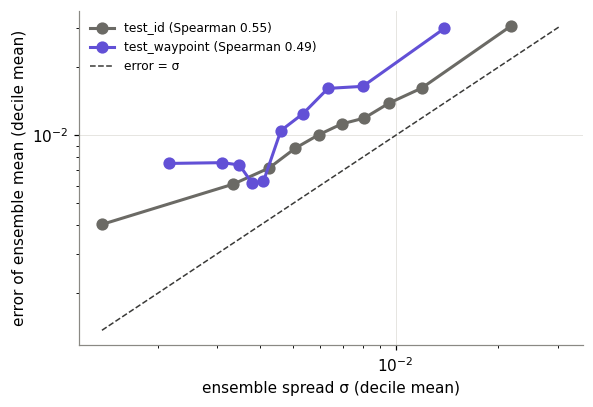

In [21]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
rows = {}
for s in ["test_id", "test_waypoint"]:
    e = EVAL["ensemble"][s]
    ax.loglog(e["bin_sigma"], e["bin_err"], marker="o", ms=7, color=COL[s], label=f"{s} (Spearman {e['spearman']:.2f})")
    rows[s] = {"NMSE ensemble mean": e["nmse_mean"], "NMSE members (mean)": np.mean(e["nmse_members"]),
               "NMSE members (min–max)": f"{min(e['nmse_members']):.2e} – {max(e['nmse_members']):.2e}", "Spearman(σ, error)": e["spearman"]}
lo = min(min(EVAL["ensemble"][s]["bin_sigma"]) for s in rows); hi = max(max(EVAL["ensemble"][s]["bin_err"]) for s in rows)
ax.plot([lo, hi], [lo, hi], color=COL["sim"], ls="--", lw=1, label="error = σ")
ax.set_xlabel("ensemble spread σ (decile mean)"); ax.set_ylabel("error of ensemble mean (decile mean)"); ax.legend(fontsize=8)
fig.tight_layout(); display(pd.DataFrame(rows).T)

### Metric 8 — cost

In [22]:
c = EVAL["cost"]; inf = c["m1_inference"]
rows = [{"item": "simulator (ssl-sim), one 1/60 s step incl. 17 substeps, CPU", "value": c["sim_us_per_step"], "unit": "µs"},
        {"item": "M1 forward, torch CPU, batch 1, 1 thread", "value": inf["torch_cpu_batch1_us"], "unit": "µs"},
        {"item": "M1 forward, ONNX Runtime CPU, batch 1, 1 thread", "value": inf.get("onnx_cpu_batch1_us", np.nan), "unit": "µs"},
        {"item": "M1 forward, GPU (RTX 5090), batch 4096, per sample", "value": inf.get("torch_gpu_batch4096_us_per_sample", np.nan), "unit": "µs"},
        {"item": "M1 / M2 parameters", "value": c["models"]["M1"]["params"], "unit": ""},
        {"item": "B2 parameters", "value": c["models"]["B2"]["params"], "unit": ""},
        {"item": "M1 training time (12k steps, GPU)", "value": c["models"]["M1"]["train_seconds"], "unit": "s"},
        {"item": "M2 fine-tune time (3k steps, BPTT 60, GPU)", "value": c["models"]["M2"]["train_seconds"], "unit": "s"},
        {"item": "dataset generation, 1.2 M transitions", "value": DS["train"].meta["sim_seconds"], "unit": "s"}]
display(pd.DataFrame(rows).set_index("item").style.format({"value": "{:.3g}"}))

,value,unit
item,,
"simulator (ssl-sim), one 1/60 s step incl. 17 substeps, CPU",0.883,µs
"M1 forward, torch CPU, batch 1, 1 thread",91.2,µs
"M1 forward, ONNX Runtime CPU, batch 1, 1 thread",24.9,µs
"M1 forward, GPU (RTX 5090), batch 4096, per sample",0.0788,µs
M1 / M2 parameters,1.35e+05,
B2 parameters,42,
"M1 training time (12k steps, GPU)",13.4,s
"M2 fine-tune time (3k steps, BPTT 60, GPU)",306,s
"dataset generation, 1.2 M transitions",0.79,s


## 6. Hypotheses

| | Hypothesis | Verdict | Evidence |
|---|---|---|---|
| H1 | M1 reaches one-step error ≪ B2, and its residual error concentrates at the saturation boundaries | **Confirmed, with a nuance** | NMSE 5.2e-4 vs 2.2e-1 (≈430× smaller). The worst regimes are the *speed cap* (`at_max_speed` 10.7 mm/s, `cmd_above_limit` 7.4 mm/s) and the in-tick clamp switch (`settling` 4.8 mm/s), vs 2.5 mm/s in `sat_accel` and 3.0 mm/s overall. The error sits at boundaries, especially the speed cap, which is also the rarest regime in train (0.5–0.7%). |
| H2 | Open-loop error grows faster than linearly with M1, and M2 reduces it at long horizons | **Confirmed** | Median position error ∝ $t^{1.20}$ (test_id) / $t^{1.27}$ (waypoint): super-linear but polynomial, with no exponential blow-up within 5 s. M2 at 5 s: 30.9 → 24.3 mm (−21%) on test_id and 42.3 → 20.6 mm (−51%) on waypoint; p95 151 → 118 mm and 122 → 65 mm. Cost: one-step NMSE slightly worse (5.2e-4 → 5.8e-4). |
| H3 | Degradation on test_waypoint is small where the excitation covers the space | **Partially confirmed** | Coverage is good (only 0.25% of waypoint samples fall in sparse train bins, despite KL = 1.33 nats), and the one-step error is even *lower* on waypoint (ratio 0.74). But M1's 1 s rollout error is **1.42× worse** on waypoint. Small one-step biases add up coherently over long, steady AI-like motions. M2 removes the gap (ratio 0.88). |

## 7. Limitations and conclusions

### Executive summary

* **The network learns the simulated robot very accurately.** One-step error is ~2 mm/s in velocity and <0.1 mm in position per tick.
  Over 1 s of open-loop simulation the median position error is **4–6 mm** (M1) and **3–4 mm** (M2); over 5 s it is **2–4 cm**.
  The linear model drifts ~30 cm in 1 s, and constant velocity ~1 m.
* **It recovers the physics without being told:** acceleration, speed and turn-rate limits within ~1%
  (α_max within 6%); step-response times within one tick; braking distance from 3 m/s within 1 mm.
* **The main limitation is drift:** errors compound slightly faster than linearly ($t^{1.2}$). Training on rollouts (M2) is the most
  effective fix found: −21% to −51% error at 5 s.
* **The one-step metric is misleading for generalization.** On AI-like driving it looked better, while the rollout was 42% worse.
  **Open-loop rollout error should be the primary metric** from now on.
* **Weak spot: the speed cap.** It is rare in the data (<1%) and has the largest error (steady speed at the cap is 2.6 cm/s low).
* **Cheap enough:** 25 µs per step on one CPU thread (ONNX), against a 16.7 ms control tick. That is ~28× slower than the
  analytic simulator (0.9 µs), but 0.08 µs per robot when 4096 robots are batched on the GPU.

### Limitations

**Of the setup**
* The simulated robot is **ideal**: deterministic, with no noise, latency, wheel slip or sensor error, and the state (including v, ω)
  is observed perfectly. This session's numbers are therefore a *best case* for how well a network can learn robot motion.
* Out of scope: walls, ball, kicks, collisions, other robots.
* Generalization was tested on a single controller style (waypoint P-controller).

**Of the models**
* An MLP with smooth activations approximates the clamps' kinks only approximately. This leaves a floor of ~2–5 mm/s per tick
  at regime boundaries.
* Rare regimes (speed cap, commands above the limit) are learned worst. No rebalancing was tried.
* M2 is a single, untuned configuration (1 s horizon, hand-picked loss scales, 3k steps, noisy training curve). Its gains are
  probably not the best achievable.
* The ensemble's spread ranks errors moderately well (Spearman 0.49–0.55) but **underestimates** them by ~2×, so it is not calibrated.
* The data-efficiency curve has only 3 points with one seed each. β = 0.58 (test_id) / 0.27 (waypoint) suggests diminishing returns:
  with 1% of the data (20 episodes) the 1 s error is already ~9–10 mm.

**Of the method**
* Process note: the first M2 training was invalid because of an aliasing bug when shifting windows to the origin. It was found by
  inspecting the rollout errors, fixed, and M2 was retrained. All numbers in this report come from the corrected run.

### Possible next experiments (still within this step)
1. Oversample the speed cap and commands above the limit, and measure the per-regime error again.
2. Tune M2: longer horizons (2–5 s), curriculum, loss scales.
3. Try non-smooth activations (ReLU / piecewise-linear) that can represent the clamp kinks exactly.
4. Add walls (position-dependent dynamics) as the next increase in difficulty.